# CISB 60 Final Project
## Predicting Patient Appointment No-Shows Using Machine Learning and Deep Learning

This project explores whether machine learning and deep learning can help predict missed healthcare appointments. I used a public healthcare dataset to compare a Random Forest model with an Artificial Neural Network and tested whether hyperparameter tuning could improve prediction performance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("KaggleV2-May-2016.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (110527, 14)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


### 1. Data types, summary statistics, and quality checks
Inspect data types, missing values, exact duplicate records, and target balance. Patient IDs and appointment IDs are identifiers, not predictive features.

In [2]:
display(df.dtypes.to_frame("dtype"))
display(df.describe(include="all").T)

print("Missing values per column:")
print(df.isna().sum())

print("Exact duplicate rows:", df.duplicated().sum())

print("Target counts:")
print(df["No-show"].value_counts())

print("Target percentages:")
print(df["No-show"].value_counts(normalize=True).mul(100).round(2))

,dtype
PatientId,float64
AppointmentID,int64
Gender,object
ScheduledDay,object
AppointmentDay,object
Age,int64
Neighbourhood,object
Scholarship,int64
Hipertension,int64
Diabetes,int64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PatientId,110527.0,NaN,NaN,NaN,147496265710394.0625,256094920291738.875,39217.84439,4172614444192.0,31731838713978.0,94391720898175.0,999981631772427.0
AppointmentID,110527.0,NaN,NaN,NaN,5675305.123427,71295.75154,5030230.0,5640285.5,5680573.0,5725523.5,5790484.0
Gender,110527,2,F,71840,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ScheduledDay,110527,103549,2016-05-06T07:09:54Z,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AppointmentDay,110527,27,2016-06-06T00:00:00Z,4692,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,110527.0,NaN,NaN,NaN,37.088874,23.110205,-1.0,18.0,37.0,55.0,115.0
Neighbourhood,110527,81,JARDIM CAMBURI,7717,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Scholarship,110527.0,NaN,NaN,NaN,0.098266,0.297675,0.0,0.0,0.0,0.0,1.0
Hipertension,110527.0,NaN,NaN,NaN,0.197246,0.397921,0.0,0.0,0.0,0.0,1.0
Diabetes,110527.0,NaN,NaN,NaN,0.071865,0.258265,0.0,0.0,0.0,0.0,1.0


Missing values per column:
PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64
Exact duplicate rows: 0
Target counts:
No-show
No     88208
Yes    22319
Name: count, dtype: int64
Target percentages:
No-show
No     79.81
Yes    20.19
Name: proportion, dtype: float64


### 2. Date processing and data quality
Calculate waiting days using calendar dates. Exclude impossible ages and negative waits after inspecting their counts. We will not use post-appointment information as model inputs.

In [3]:
df["ScheduledDay"] = pd.to_datetime(df["ScheduledDay"], utc=True)
df["AppointmentDay"] = pd.to_datetime(df["AppointmentDay"], utc=True)

df["waiting_days"] = (
    df["AppointmentDay"].dt.normalize()
    - df["ScheduledDay"].dt.normalize()
).dt.days

print("Negative ages:", (df["Age"] < 0).sum())
print("Negative waiting days:", (df["waiting_days"] < 0).sum())

print("Handcap values:")
print(df["Handcap"].value_counts().sort_index())

clean = df.loc[
    (df["Age"] >= 0) & (df["waiting_days"] >= 0)
].copy()

clean["appointment_weekday"] = clean["AppointmentDay"].dt.day_name()
clean["scheduled_weekday"] = clean["ScheduledDay"].dt.day_name()

clean["missed"] = (clean["No-show"] == "Yes").astype(int)

print("Rows after filtering:", len(clean))

Negative ages: 1
Negative waiting days: 5
Handcap values:
Handcap
0    108286
1      2042
2       183
3        13
4         3
Name: count, dtype: int64
Rows after filtering: 110521


### 3. Exploratory visualizations
These descriptive plots use the full dataset to explain its characteristics. Later, model transformations are fitted on training data only.

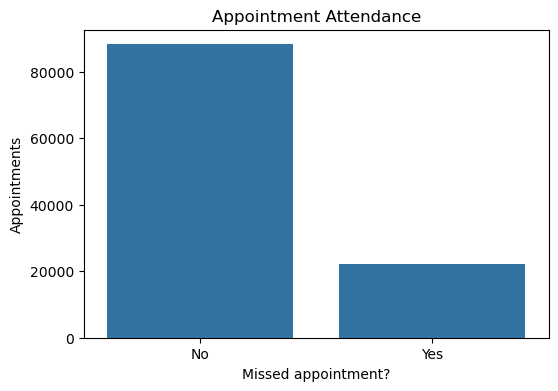

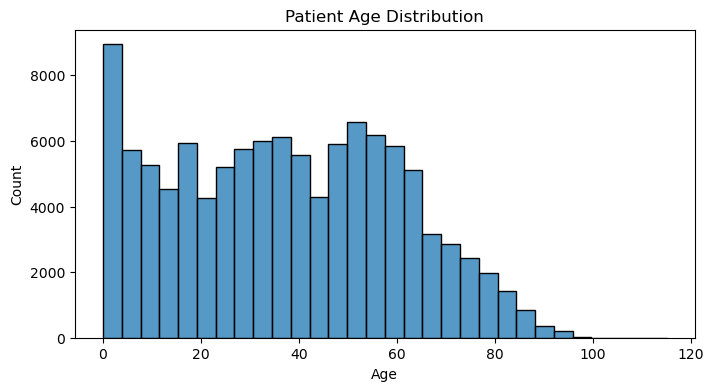

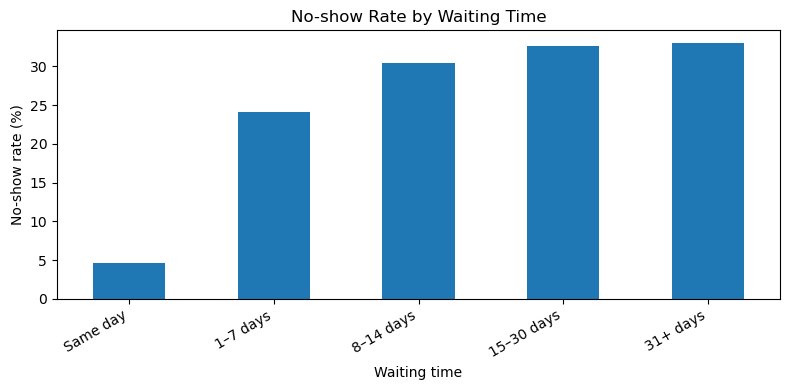

In [4]:
fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(data=clean, x="No-show", order=["No", "Yes"], ax=ax)
ax.set(title="Appointment Attendance", xlabel="Missed appointment?", ylabel="Appointments")
plt.show()

fig, ax = plt.subplots(figsize=(8,4))
sns.histplot(data=clean, x="Age", bins=30, ax=ax)
ax.set(title="Patient Age Distribution")
plt.show()

clean["wait_group"] = pd.cut(clean["waiting_days"], bins=[-1,0,7,14,30,np.inf], labels=["Same day","1–7 days","8–14 days","15–30 days","31+ days"])
rate = clean.groupby("wait_group", observed=False)["missed"].mean().mul(100)
fig, ax = plt.subplots(figsize=(8,4))
rate.plot.bar(ax=ax)
ax.set(title="No-show Rate by Waiting Time", ylabel="No-show rate (%)", xlabel="Waiting time")
plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.show()

### 4. Training and testing data (leakage-aware)
We split before fitting imputation, encoding, or scaling. A stratified split preserves approximate class balance. Because patients can have multiple appointments, a future improvement would be a patient-grouped or chronological evaluation. The SMS variable is included provisionally; whether it was known at the intended prediction time must be verified.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

features = ["Gender", "Age", "Neighbourhood", "Scholarship", "Hipertension", "Diabetes", "Alcoholism", "Handcap", "SMS_received", "waiting_days", "appointment_weekday", "scheduled_weekday"]
X = clean[features].copy()
y = clean["missed"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
categorical = ["Gender", "Neighbourhood", "appointment_weekday", "scheduled_weekday"]
numeric = [c for c in features if c not in categorical]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical)
])
print("Training rows:", len(X_train), "Testing rows:", len(X_test))
print("Training no-show rate:", round(y_train.mean()*100,2), "%")
print("Testing no-show rate:", round(y_test.mean()*100,2), "%")

Training rows: 88416 Testing rows: 22105
Training no-show rate: 20.19 %
Testing no-show rate: 20.19 %


### Exploratory Data Analysis Interpretation

After reviewing the dataset, I found that most patients attended their scheduled appointments, while approximately 20% missed theirs. There were no missing values or duplicate records, but I did remove six records because of invalid ages or appointment waiting times.

Looking at the age distribution, I noticed that the dataset includes patients of all ages, with a large number of younger patients and adults between 30 and 60 years old. There were fewer appointments involving patients over 60.

What stood out to me the most was the relationship between waiting time and missed appointments. Patients with same-day appointments had a no-show rate of around 5%, while patients who waited more than 30 days had a no-show rate of approximately 33%. Even patients waiting just 1 to 7 days had a noticeably higher no-show rate of around 24%.

Working in healthcare, I can see why this information could be useful. If longer waiting times are associated with more missed appointments, healthcare facilities might benefit from sending additional reminders or reaching out to patients who have appointments scheduled further out.

These findings helped me understand which factors might be useful when building my prediction models. However, the charts show patterns in the data and don't necessarily mean that longer waiting times directly cause patients to miss appointments.

Random Forest Model Results
---------------------------
Accuracy: 0.778
Precision: 0.4017
Recall: 0.2032
F1 Score: 0.2699

Classification Report:
              precision    recall  f1-score   support

    Attended       0.82      0.92      0.87     17642
     No-Show       0.40      0.20      0.27      4463

    accuracy                           0.78     22105
   macro avg       0.61      0.56      0.57     22105
weighted avg       0.74      0.78      0.75     22105



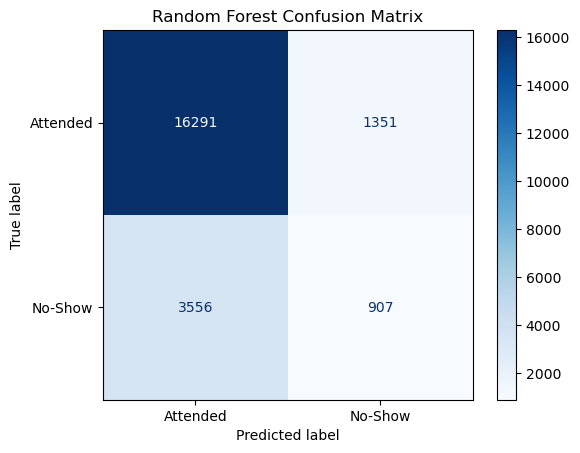

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Create the Random Forest model
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model using training data
rf_model.fit(X_train, y_train)

# Make predictions on testing data
y_pred_rf = rf_model.predict(X_test)

# Evaluate model performance
print("Random Forest Model Results")
print("---------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_rf, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Attended", "No-Show"],
    zero_division=0
))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["Attended", "No-Show"],
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

### Random Forest Model Interpretation

For this part of my project, I used a Random Forest Classifier to predict whether patients would miss their scheduled appointments. The model achieved an accuracy of 77.80%, which initially seemed pretty good. However, after reviewing the other performance metrics, I noticed that the model had difficulty identifying patients who actually missed their appointments.

The precision for predicting no-shows was 40.17%, while recall was only 20.32%. Out of 4,463 patients who missed their appointments, the model correctly identified 907 and failed to identify 3,556.

This shows why accuracy alone is not always the best way to evaluate a machine learning model, especially when one outcome happens more frequently than another.

From a healthcare business perspective, identifying patients who might miss their appointments could help organizations improve scheduling and use their resources more efficiently. However, this model would need improvement before it could be considered reliable for identifying patients at risk of missing appointments.

### Random Forest Feature Importance

Top 15 Most Important Features:


,Feature,Importance
0,num__Age,0.314443
7,num__waiting_days,0.186170
6,num__SMS_received,0.021136
8,cat__Gender_F,0.016672
9,cat__Gender_M,0.016551
101,cat__scheduled_weekday_Tuesday,0.014707
102,cat__scheduled_weekday_Wednesday,0.014349
95,cat__appointment_weekday_Tuesday,0.013408
98,cat__scheduled_weekday_Monday,0.013200
97,cat__scheduled_weekday_Friday,0.013060


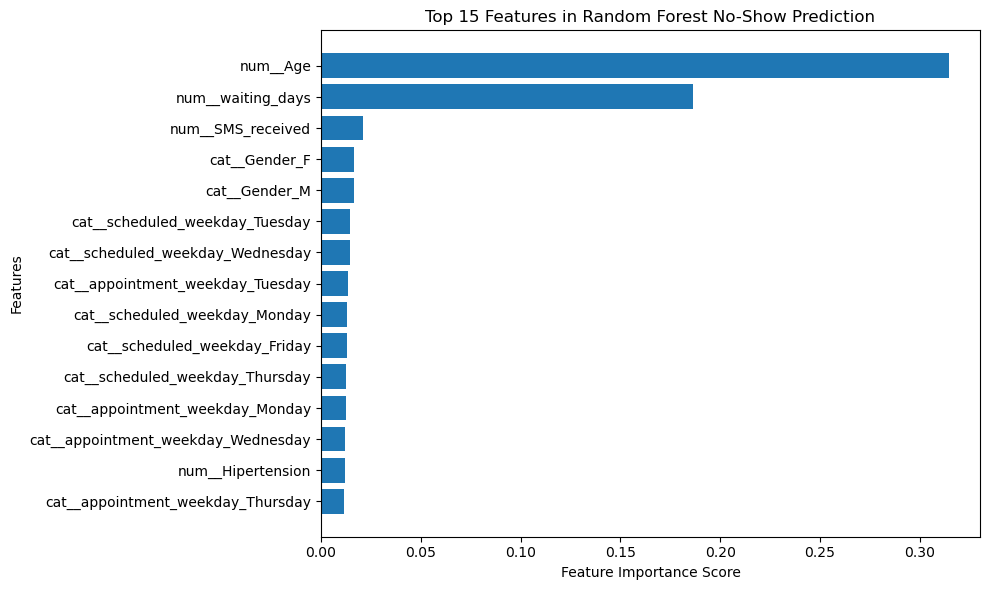

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance scores
importances = rf_model.named_steps[
    "classifier"
].feature_importances_

# Create a table of features and importance scores
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort features from highest to lowest importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
print("Top 15 Most Important Features:")
display(feature_importance_df.head(15))

# Create a horizontal bar chart
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance Score")
plt.ylabel("Features")
plt.title("Top 15 Features in Random Forest No-Show Prediction")

plt.tight_layout()
plt.show()

### Feature Importance Interpretation

After reviewing my Random Forest feature importance chart, I noticed that patient age and the number of days between scheduling and the appointment were the two most important individual features used by the model.

Age had an importance score of approximately 31.5%, while waiting days had a score of 18.62%. Other features, including SMS reminders, gender, and appointment weekdays, had lower individual importance scores.

One thing I found interesting was how much more the model relied on age and waiting time compared to most of the other features. This suggests these variables are worth investigating further when trying to understand appointment attendance.

From a healthcare business perspective, understanding these patterns could help organizations explore better scheduling and patient outreach strategies. However, feature importance does not necessarily mean that these factors cause patients to miss their appointments.

In [8]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("TensorFlow is ready!")

TensorFlow Version: 2.21.0
TensorFlow is ready!


## Deep Learning: Artificial Neural Network (ANN)

In [9]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Create a validation set from the training data
X_ann_train, X_ann_val, y_ann_train, y_ann_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Apply preprocessing using training data only
X_ann_train_processed = preprocessor.fit_transform(X_ann_train)
X_ann_val_processed = preprocessor.transform(X_ann_val)
X_ann_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices to dense arrays for TensorFlow
def to_dense(matrix):
    if hasattr(matrix, "toarray"):
        return matrix.toarray().astype("float32")
    return np.asarray(matrix, dtype="float32")

X_ann_train_processed = to_dense(X_ann_train_processed)
X_ann_val_processed = to_dense(X_ann_val_processed)
X_ann_test_processed = to_dense(X_ann_test_processed)

print("ANN training shape:", X_ann_train_processed.shape)
print("ANN validation shape:", X_ann_val_processed.shape)
print("ANN testing shape:", X_ann_test_processed.shape)

ANN training shape: (70732, 103)
ANN validation shape: (17684, 103)
ANN testing shape: (22105, 103)


In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Build the Artificial Neural Network
ann_model = Sequential([
    Input(shape=(X_ann_train_processed.shape[1],)),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(32, activation="relu"),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

# Compile the model
ann_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           6,656 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 8,769 (34.25 KB)

 Trainable params: 8,769 (34.25 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
from tensorflow.keras.callbacks import EarlyStopping

# Stop training when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train the neural network
history = ann_model.fit(
    X_ann_train_processed,
    y_ann_train,
    validation_data=(
        X_ann_val_processed,
        y_ann_val
    ),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("ANN training completed!")

Epoch 1/30
2211/2211 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.7969 - loss: 0.4739 - val_accuracy: 0.7981 - val_loss: 0.4510
Epoch 2/30
2211/2211 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.7981 - loss: 0.4566 - val_accuracy: 0.7981 - val_loss: 0.4443
Epoch 3/30
2211/2211 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7982 - loss: 0.4502 - val_accuracy: 0.7982 - val_loss: 0.4422
Epoch 4/30
2211/2211 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7980 - loss: 0.4471 - val_accuracy: 0.7984 - val_loss: 0.4416
Epoch 5/30
2211/2211 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.7982 - loss: 0.4458 - val_accuracy: 0.7984 - val_loss: 0.4408
Epoch 6/30
2211/2211 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7982 - loss: 0.4438 - val_accuracy: 0.7985 - val_loss: 0.4403
Epoch 7/30
2211/2211 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7985 - loss: 0.4433 - val_accuracy: 0.7984 - val_loss: 0.4400
Epoch 8/30
2211/2211 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7986 - loss: 0.4416 - 

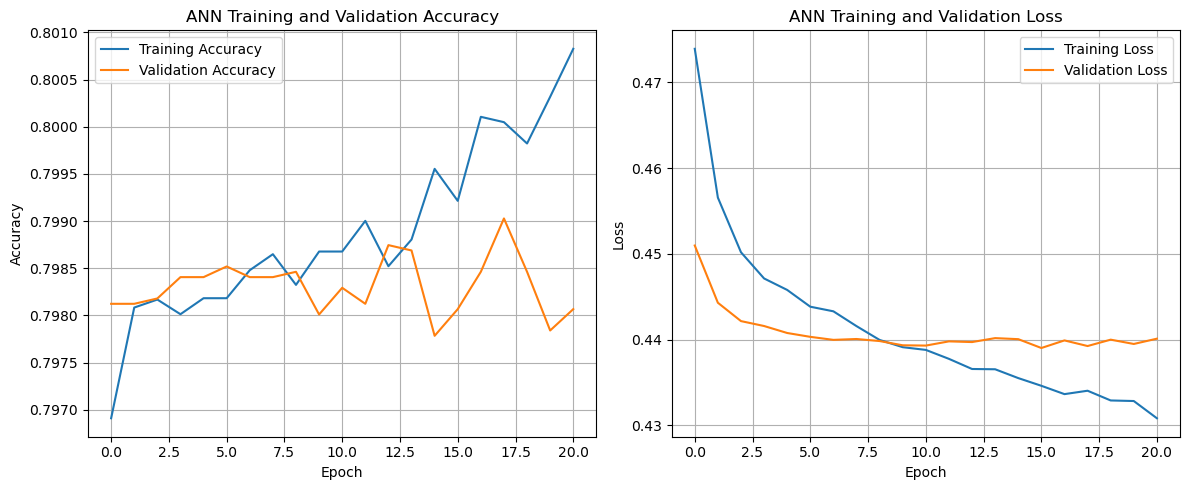

In [12]:
import matplotlib.pyplot as plt

# Create accuracy and loss charts
plt.figure(figsize=(12, 5))

# Accuracy chart
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss chart
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### ANN Training and Validation Interpretation

After training my Artificial Neural Network, I reviewed the training and validation accuracy and loss graphs to see how well the model was learning.

The model completed 21 epochs before early stopping ended the training process. Training accuracy gradually increased to approximately 80.08%, while validation accuracy remained around 79.81%.

I also noticed that training loss continued decreasing throughout the process, but validation loss stopped improving after the earlier epochs. This suggests the model may have started overfitting slightly because it continued improving on the training data without showing much improvement on the validation data.

One thing I found interesting was that the accuracy remained close to 80%, which is also approximately the percentage of patients who attended their appointments. Because of this, I still need to evaluate precision, recall, and F1-score to determine whether the model can actually identify patients who are likely to miss appointments.

691/691 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Artificial Neural Network Results
---------------------------------
Accuracy: 0.7982
Precision: 0.5094
Recall: 0.0181
F1 Score: 0.035

Classification Report:
              precision    recall  f1-score   support

    Attended       0.80      1.00      0.89     17642
     No-Show       0.51      0.02      0.04      4463

    accuracy                           0.80     22105
   macro avg       0.65      0.51      0.46     22105
weighted avg       0.74      0.80      0.72     22105



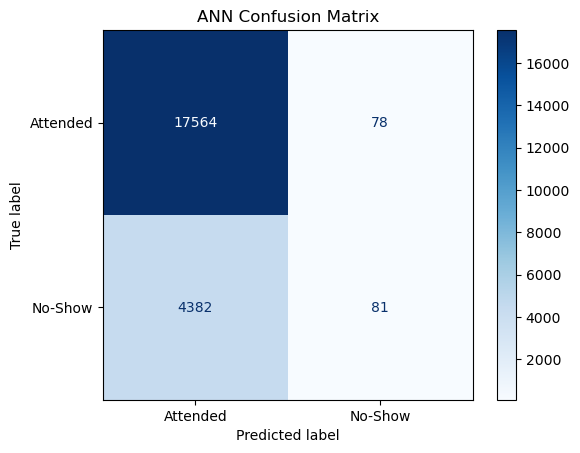

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict no-show probabilities
ann_probabilities = ann_model.predict(
    X_ann_test_processed
).ravel()

# Convert probabilities to predictions
# 0 = Attended, 1 = No-Show
y_pred_ann = (ann_probabilities >= 0.5).astype(int)

# Calculate evaluation metrics
ann_accuracy = accuracy_score(y_test, y_pred_ann)
ann_precision = precision_score(
    y_test, y_pred_ann, zero_division=0
)
ann_recall = recall_score(
    y_test, y_pred_ann, zero_division=0
)
ann_f1 = f1_score(
    y_test, y_pred_ann, zero_division=0
)

print("Artificial Neural Network Results")
print("---------------------------------")
print("Accuracy:", round(ann_accuracy, 4))
print("Precision:", round(ann_precision, 4))
print("Recall:", round(ann_recall, 4))
print("F1 Score:", round(ann_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_ann,
    target_names=["Attended", "No-Show"],
    zero_division=0
))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_ann,
    display_labels=["Attended", "No-Show"],
    cmap="Blues"
)

plt.title("ANN Confusion Matrix")
plt.show()

### Machine Learning vs. Deep Learning Model Comparison

After evaluating both models, I noticed that the Artificial Neural Network achieved slightly higher accuracy than the Random Forest model. The ANN had an accuracy of 79.82%, compared to 77.80% for Random Forest.

However, when I looked at recall and F1-score, the results told a different story. Random Forest correctly identified 907 missed appointments, while the ANN only identified 81 out of 4,463 actual no-shows.

The ANN had a recall of just 1.81%, compared to 20.32% for Random Forest. This means the ANN missed almost all of the patients who did not attend their appointments.

One thing I learned from comparing these models is that higher accuracy does not necessarily mean a model is better. Since the goal of my project is to identify patients who may miss appointments, recall is especially important.

Based on these results, Random Forest is currently the better option for this business problem. However, both models would need improvement before they could be used reliably in a healthcare setting.

In [14]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Compare both models using the same test data
comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Random Forest": [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],
    "ANN": [
        accuracy_score(y_test, y_pred_ann),
        precision_score(y_test, y_pred_ann, zero_division=0),
        recall_score(y_test, y_pred_ann, zero_division=0),
        f1_score(y_test, y_pred_ann, zero_division=0)
    ]
})

display(comparison_df.round(4))

,Metric,Random Forest,ANN
0,Accuracy,0.7780,0.7982
1,Precision,0.4017,0.5094
2,Recall,0.2032,0.0181
3,F1 Score,0.2699,0.0350


## Hyperparameter Tuning and Model Optimization

In [15]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create a new Random Forest pipeline
tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# Hyperparameters to test
param_grid = {
    "classifier__n_estimators": [50, 100],
    "classifier__max_depth": [10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__class_weight": [None, "balanced"]
}

# Use cross-validation to find the best settings
grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=2,
    verbose=2
)

# Train using only training data
grid_search.fit(X_train, y_train)

# Display the best parameters
print("Best Hyperparameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(grid_search.best_score_, 4))

# Save the tuned model
best_rf_model = grid_search.best_estimator_

print("\nHyperparameter tuning completed!")

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best Hyperparameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 20, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}

Best Cross-Validation F1 Score:
0.4496

Hyperparameter tuning completed!


Tuned Random Forest Results
---------------------------
Accuracy: 0.6305
Precision: 0.3198
Recall: 0.7363
F1 Score: 0.4459

Classification Report:
              precision    recall  f1-score   support

    Attended       0.90      0.60      0.72     17642
     No-Show       0.32      0.74      0.45      4463

    accuracy                           0.63     22105
   macro avg       0.61      0.67      0.58     22105
weighted avg       0.78      0.63      0.67     22105



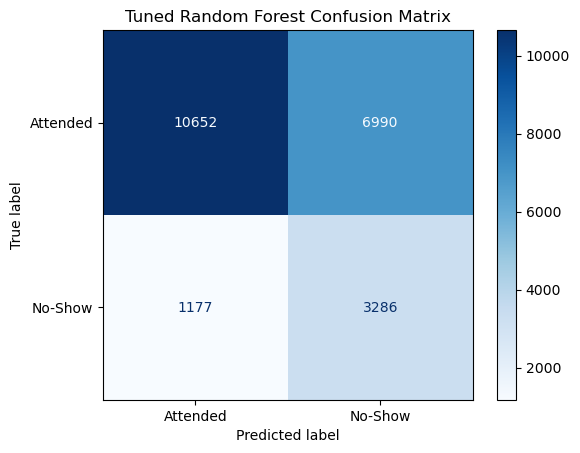

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict using the tuned Random Forest
y_pred_tuned = best_rf_model.predict(X_test)

# Calculate tuned model performance
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_precision = precision_score(
    y_test, y_pred_tuned, zero_division=0
)
tuned_recall = recall_score(
    y_test, y_pred_tuned, zero_division=0
)
tuned_f1 = f1_score(
    y_test, y_pred_tuned, zero_division=0
)

print("Tuned Random Forest Results")
print("---------------------------")
print("Accuracy:", round(tuned_accuracy, 4))
print("Precision:", round(tuned_precision, 4))
print("Recall:", round(tuned_recall, 4))
print("F1 Score:", round(tuned_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Attended", "No-Show"],
    zero_division=0
))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=["Attended", "No-Show"],
    cmap="Blues"
)

plt.title("Tuned Random Forest Confusion Matrix")
plt.show()

### Hyperparameter Tuning Results and Interpretation

For this part of my project, I used GridSearchCV to improve my Random Forest model. I tested 16 different combinations of hyperparameters using 3-fold cross-validation. The best settings included 100 trees, a maximum depth of 20, a minimum sample split of 5, and balanced class weights.

After tuning, I noticed a significant improvement in the model's ability to identify missed appointments. Recall increased from 20.32% to 73.63%, and the F1-score increased from 26.99% to 44.59%.

Before tuning, the model correctly identified 907 missed appointments. After tuning, it correctly identified 3,286 out of 4,463 actual no-shows.

However, accuracy decreased from 77.80% to 63.05%, and precision also decreased. The tuned model incorrectly predicted that 6,990 patients would miss their appointments even though they actually attended.

This showed me that improving one performance metric can sometimes come at the expense of another. For this project, I think improving recall is valuable because the main goal is to identify patients who may miss their appointments.

From a healthcare business perspective, the tuned model could potentially help organizations identify more patients who may benefit from appointment reminders. However, the number of false positives would need to be considered because unnecessary outreach could increase operational costs.

,Metric,Baseline Random Forest,Tuned Random Forest
0,Accuracy,0.7780,0.6305
1,Precision,0.4017,0.3198
2,Recall,0.2032,0.7363
3,F1 Score,0.2699,0.4459


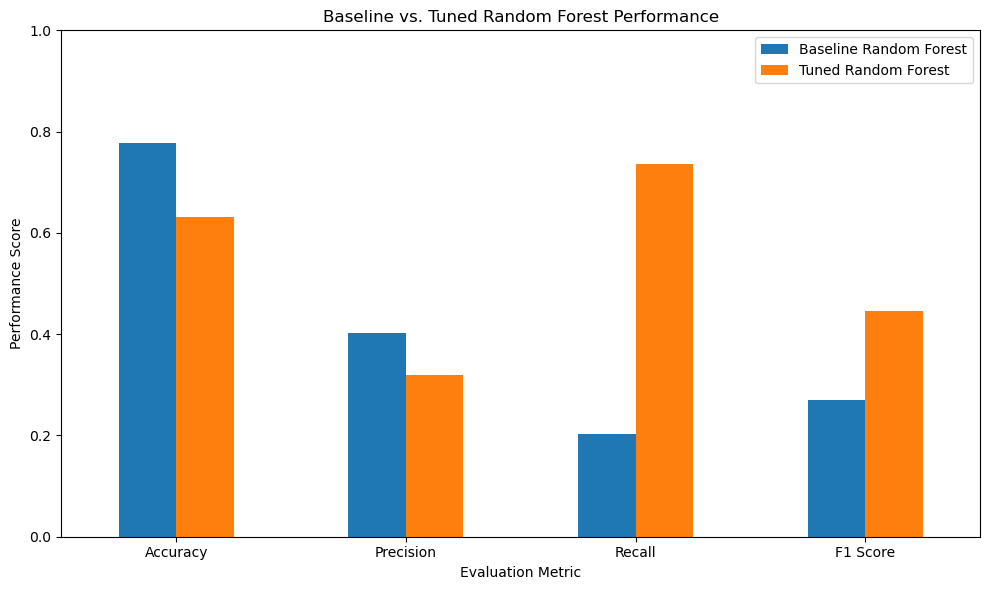

In [17]:
# Compare baseline and tuned Random Forest models
tuning_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Baseline Random Forest": [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],
    "Tuned Random Forest": [
        accuracy_score(y_test, y_pred_tuned),
        precision_score(y_test, y_pred_tuned, zero_division=0),
        recall_score(y_test, y_pred_tuned, zero_division=0),
        f1_score(y_test, y_pred_tuned, zero_division=0)
    ]
})

display(tuning_comparison.round(4))

# Visualize the performance comparison
comparison_plot = tuning_comparison.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6),
    rot=0
)

plt.title("Baseline vs. Tuned Random Forest Performance")
plt.ylabel("Performance Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

## Final Project Conclusion

For my CISB 60 final project, I explored how machine learning and deep learning could be used to predict missed healthcare appointments.

I developed a Random Forest model and an Artificial Neural Network using TensorFlow and Keras. I evaluated both models using accuracy, precision, recall, and F1-score.

The original Random Forest model achieved 77.80% accuracy, while the ANN achieved 79.82%. However, Random Forest performed better at identifying patients who actually missed their appointments.

After using GridSearchCV to optimize the Random Forest model, recall improved from 20.32% to 73.63%, and the F1-score increased from 26.99% to 44.59%.

Although tuning improved the model's ability to detect no-shows, it also increased false-positive predictions and reduced overall accuracy. This showed me that selecting the best model depends on the business objective rather than accuracy alone.

From a healthcare operations perspective, predicting missed appointments could potentially help organizations improve scheduling, reduce wasted resources, and identify patients who may benefit from additional reminders.

However, the models still have limitations. The dataset contains historical appointment information from Brazil, and the results may not generalize to other healthcare organizations. The predictions would also need further validation before being used in real healthcare operations.

Overall, this project helped me understand how machine learning and deep learning can be applied to a real business problem and how important it is to evaluate models using metrics that align with the organization's goals.

## References

Hoppen, J. Medical Appointment No Shows. Kaggle.
https://www.kaggle.com/datasets/joniarroba/noshowappointments/data